In [21]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

data = pd.read_csv("stroke_zaj1.csv", decimal=",", sep=";")
print(data.head())

   gender  age  hypertension  heart_disease ever_married      work_type  \
0    Male   67             0              1          Yes        Private   
1    Male   80             0              1          Yes        Private   
2  Female   49             0              0          Yes        Private   
3  Female   79             1              0          Yes  Self-employed   
4    Male   81             0              0          Yes        Private   

  Residence_type  avg_glucose_level   bmi   smoking_status  stroke  
0          Urban             228.69  36.6  formerly smoked       1  
1          Rural             105.92  32.5     never smoked       1  
2            NaN             171.23  34.4           smokes       1  
3          Rural             174.12  24.0     never smoked       1  
4          Urban             186.21  29.0  formerly smoked       1  


In [22]:
# Sprawdzenie typów danych i ile jest obserwacji
print(data.shape)
data.info()

(612, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 612 entries, 0 to 611
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             612 non-null    object 
 1   age                612 non-null    int64  
 2   hypertension       612 non-null    int64  
 3   heart_disease      612 non-null    int64  
 4   ever_married       612 non-null    object 
 5   work_type          557 non-null    object 
 6   Residence_type     552 non-null    object 
 7   avg_glucose_level  568 non-null    float64
 8   bmi                549 non-null    float64
 9   smoking_status     612 non-null    object 
 10  stroke             612 non-null    int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 52.7+ KB


In [23]:
# Podstawowe statystyki dla zmiennych liczbowych
print(data.describe())

              age  hypertension  heart_disease  avg_glucose_level         bmi  \
count  612.000000    612.000000     612.000000         568.000000  549.000000   
mean    52.632353      0.158497       0.096405         116.235352   30.420036   
std     20.709916      0.365505       0.295388          53.497575    7.044442   
min      5.000000      0.000000       0.000000          55.390000   14.600000   
25%     39.000000      0.000000       0.000000          78.785000   25.600000   
50%     54.000000      0.000000       0.000000          95.925000   29.300000   
75%     70.000000      0.000000       0.000000         129.505000   34.400000   
max     82.000000      1.000000       1.000000         271.740000   56.600000   

           stroke  
count  612.000000  
mean     0.341503  
std      0.474602  
min      0.000000  
25%      0.000000  
50%      0.000000  
75%      1.000000  
max      1.000000  


In [24]:
# Sprawdzenie wartości i liczebności w kolumnach kategorycznych
for kolumna in data.select_dtypes(include="object").columns:
    print("\n")
    print(data[kolumna].value_counts(dropna=False))



gender
Female    355
Male      257
Name: count, dtype: int64


ever_married
Yes    480
No     132
Name: count, dtype: int64


work_type
Private          340
Self-employed    112
Govt_job          77
NaN               55
children          28
Name: count, dtype: int64


Residence_type
Urban    289
Rural    263
NaN       60
Name: count, dtype: int64


smoking_status
never smoked       238
formerly smoked    141
Unknown            123
smokes             110
Name: count, dtype: int64


In [25]:
# Sprawdzenie, w których kolumnach są braki danych
braki = data.isna().sum()
print(braki[braki > 0])

work_type            55
Residence_type       60
avg_glucose_level    44
bmi                  63
dtype: int64


In [26]:
# Zapisanie statystyk przed uzupełnieniem braków
kolumny_liczbowe = data.select_dtypes(include=np.number).columns.drop("stroke")
statystyki_przed = data[kolumny_liczbowe].agg(["mean", "median", "std"]).T
statystyki_przed

,mean,median,std
age,52.632353,54.000,20.709916
hypertension,0.158497,0.000,0.365505
heart_disease,0.096405,0.000,0.295388
avg_glucose_level,116.235352,95.925,53.497575
bmi,30.420036,29.300,7.044442


In [27]:
# Uzupełnienie braków w kopiach danych, żeby móc porównać różne metody
data_srednia = data.copy()
data_mediana = data.copy()
data_moda = data.copy()

for kolumna in kolumny_liczbowe:
    data_srednia[kolumna] = data_srednia[kolumna].fillna(data_srednia[kolumna].mean())
    data_mediana[kolumna] = data_mediana[kolumna].fillna(data_mediana[kolumna].median())

kolumny_kategoryczne = data.select_dtypes(include="object").columns
for kolumna in kolumny_kategoryczne:
    data_moda[kolumna] = data_moda[kolumna].fillna(data_moda[kolumna].mode()[0])

In [28]:
# Porównanie statystyk przed uzupełnieniem braków i po zastosowaniu średniej oraz mediany
porownanie = pd.concat({
    "Przed": data[kolumny_liczbowe].agg(["mean", "median", "std"]).T,
    "Średnia": data_srednia[kolumny_liczbowe].agg(["mean", "median", "std"]).T,
    "Mediana": data_mediana[kolumny_liczbowe].agg(["mean", "median", "std"]).T
}, axis=1)

porownanie.round(2)

Przed               Średnia               Mediana         \
                     mean median    std    mean median    std    mean median   
age                 52.63  54.00  20.71   52.63  54.00  20.71   52.63  54.00   
hypertension         0.16   0.00   0.37    0.16   0.00   0.37    0.16   0.00   
heart_disease        0.10   0.00   0.30    0.10   0.00   0.30    0.10   0.00   
avg_glucose_level  116.24  95.92  53.50  116.24  98.60  51.54  114.78  95.92   
bmi                 30.42  29.30   7.04   30.42  30.15   6.67   30.30  29.30   

                          
                     std  
age                20.71  
hypertension        0.37  
heart_disease       0.30  
avg_glucose_level  51.80  
bmi                 6.68

In [29]:
# Podział na zbiór uczący i testowy.
X = data.drop(columns="stroke")
y = data["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_train = X_train.copy()
X_test = X_test.copy()

In [30]:
print("Zbiór uczący:", X_train.shape)
print("Zbiór testowy:", X_test.shape)
print("\nUdział klas w całym zbiorze:")
print(y.value_counts(normalize=True).sort_index())
print("\nUdział klas w zbiorze uczącym:")
print(y_train.value_counts(normalize=True).sort_index())
print("\nUdział klas w zbiorze testowym:")
print(y_test.value_counts(normalize=True).sort_index())

Zbiór uczący: (489, 10)
Zbiór testowy: (123, 10)

Udział klas w całym zbiorze:
stroke
0    0.658497
1    0.341503
Name: proportion, dtype: float64

Udział klas w zbiorze uczącym:
stroke
0    0.658487
1    0.341513
Name: proportion, dtype: float64

Udział klas w zbiorze testowym:
stroke
0    0.658537
1    0.341463
Name: proportion, dtype: float64


In [31]:
# Zmienne liczbowe: mediana wyliczona tylko na zbiorze uczącym
imputer_num = SimpleImputer(strategy="median")
imputer_num.fit(X_train[kolumny_liczbowe])
X_train[kolumny_liczbowe] = imputer_num.transform(X_train[kolumny_liczbowe])
X_test[kolumny_liczbowe] = imputer_num.transform(X_test[kolumny_liczbowe])

In [32]:
# Zmienne kategoryczne: uzupełnianie proporcjonalne (proporcje ze zbioru uczącego)
rng = np.random.default_rng(42)

for kolumna in kolumny_kategoryczne:
    proporcje = X_train[kolumna].value_counts(normalize=True)

    braki = X_train[kolumna].isna()
    X_train.loc[braki, kolumna] = rng.choice(proporcje.index, size=braki.sum(), p=proporcje.values)

    braki = X_test[kolumna].isna()
    X_test.loc[braki, kolumna] = rng.choice(proporcje.index, size=braki.sum(), p=proporcje.values)

In [33]:
# Kontrola
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())

0 0


In [34]:
# Kodowanie zmiennych kategorycznych na wartości liczbowe, aby można było wykorzystać je w modelu
X_train["gender"] = X_train["gender"].map({"Male": 1, "Female": 0})
X_test["gender"] = X_test["gender"].map({"Male": 1, "Female": 0})
X_train["ever_married"] = X_train["ever_married"].map({"Yes": 1, "No": 0})
X_test["ever_married"] = X_test["ever_married"].map({"Yes": 1, "No": 0})

X_train = pd.get_dummies(
    X_train,
    columns=["work_type", "Residence_type", "smoking_status"],
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["work_type", "Residence_type", "smoking_status"],
    dtype=int
)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)
print((X_train.columns == X_test.columns).all())

True


In [35]:
print(X_train.head())

     gender   age  hypertension  heart_disease  ever_married  \
336       1  42.0           0.0            0.0             1   
427       0  57.0           0.0            0.0             1   
211       1  40.0           0.0            0.0             1   
483       1  36.0           0.0            0.0             1   
101       0  58.0           0.0            0.0             1   

     avg_glucose_level   bmi  work_type_Govt_job  work_type_Private  \
336             145.50  31.8                   0                  1   
427              93.85  29.1                   0                  1   
211              56.07  26.6                   0                  1   
483             106.85  40.1                   0                  1   
101              59.86  28.0                   0                  1   

     work_type_Self-employed  work_type_children  Residence_type_Rural  \
336                        0                   0                     1   
427                        0            

In [36]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [ ]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

### Prezentacja wyników na zbiorze uczącym

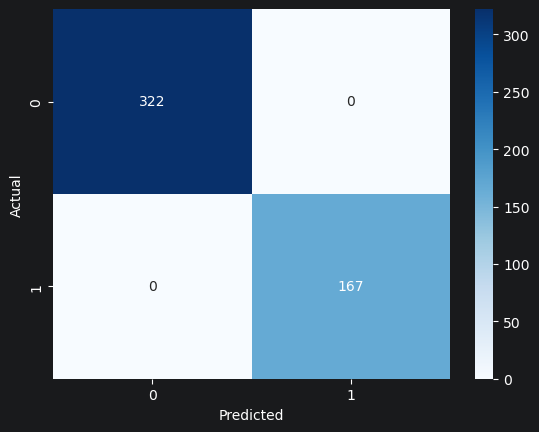

In [37]:
conf_matrix = confusion_matrix(y_train, y_pred_train)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [38]:
print(classification_report(y_train, y_pred_train))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       322
           1       1.00      1.00      1.00       167

    accuracy                           1.00       489
   macro avg       1.00      1.00      1.00       489
weighted avg       1.00      1.00      1.00       489



### Prezentacja wyników na zbiorze testowym

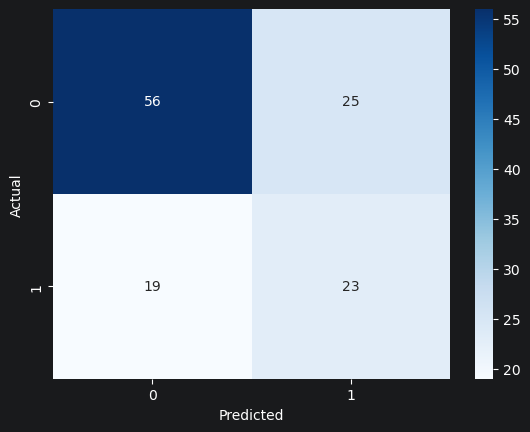

In [39]:
conf_matrix = confusion_matrix(y_test, y_pred_test)
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [40]:
print(classification_report(y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.75      0.69      0.72        81
           1       0.48      0.55      0.51        42

    accuracy                           0.64       123
   macro avg       0.61      0.62      0.61       123
weighted avg       0.66      0.64      0.65       123



### Drzewo decyzyjne

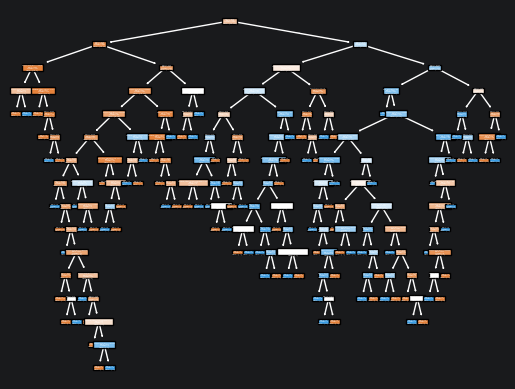

In [41]:
plot_tree(model, feature_names=X_train.columns, filled=True)
plt.show()

### Drzewo decyzyjne z ustaloną maksymalną głębokością

`max_depth` = 4

In [42]:
model2 = DecisionTreeClassifier(max_depth=3)
model2.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


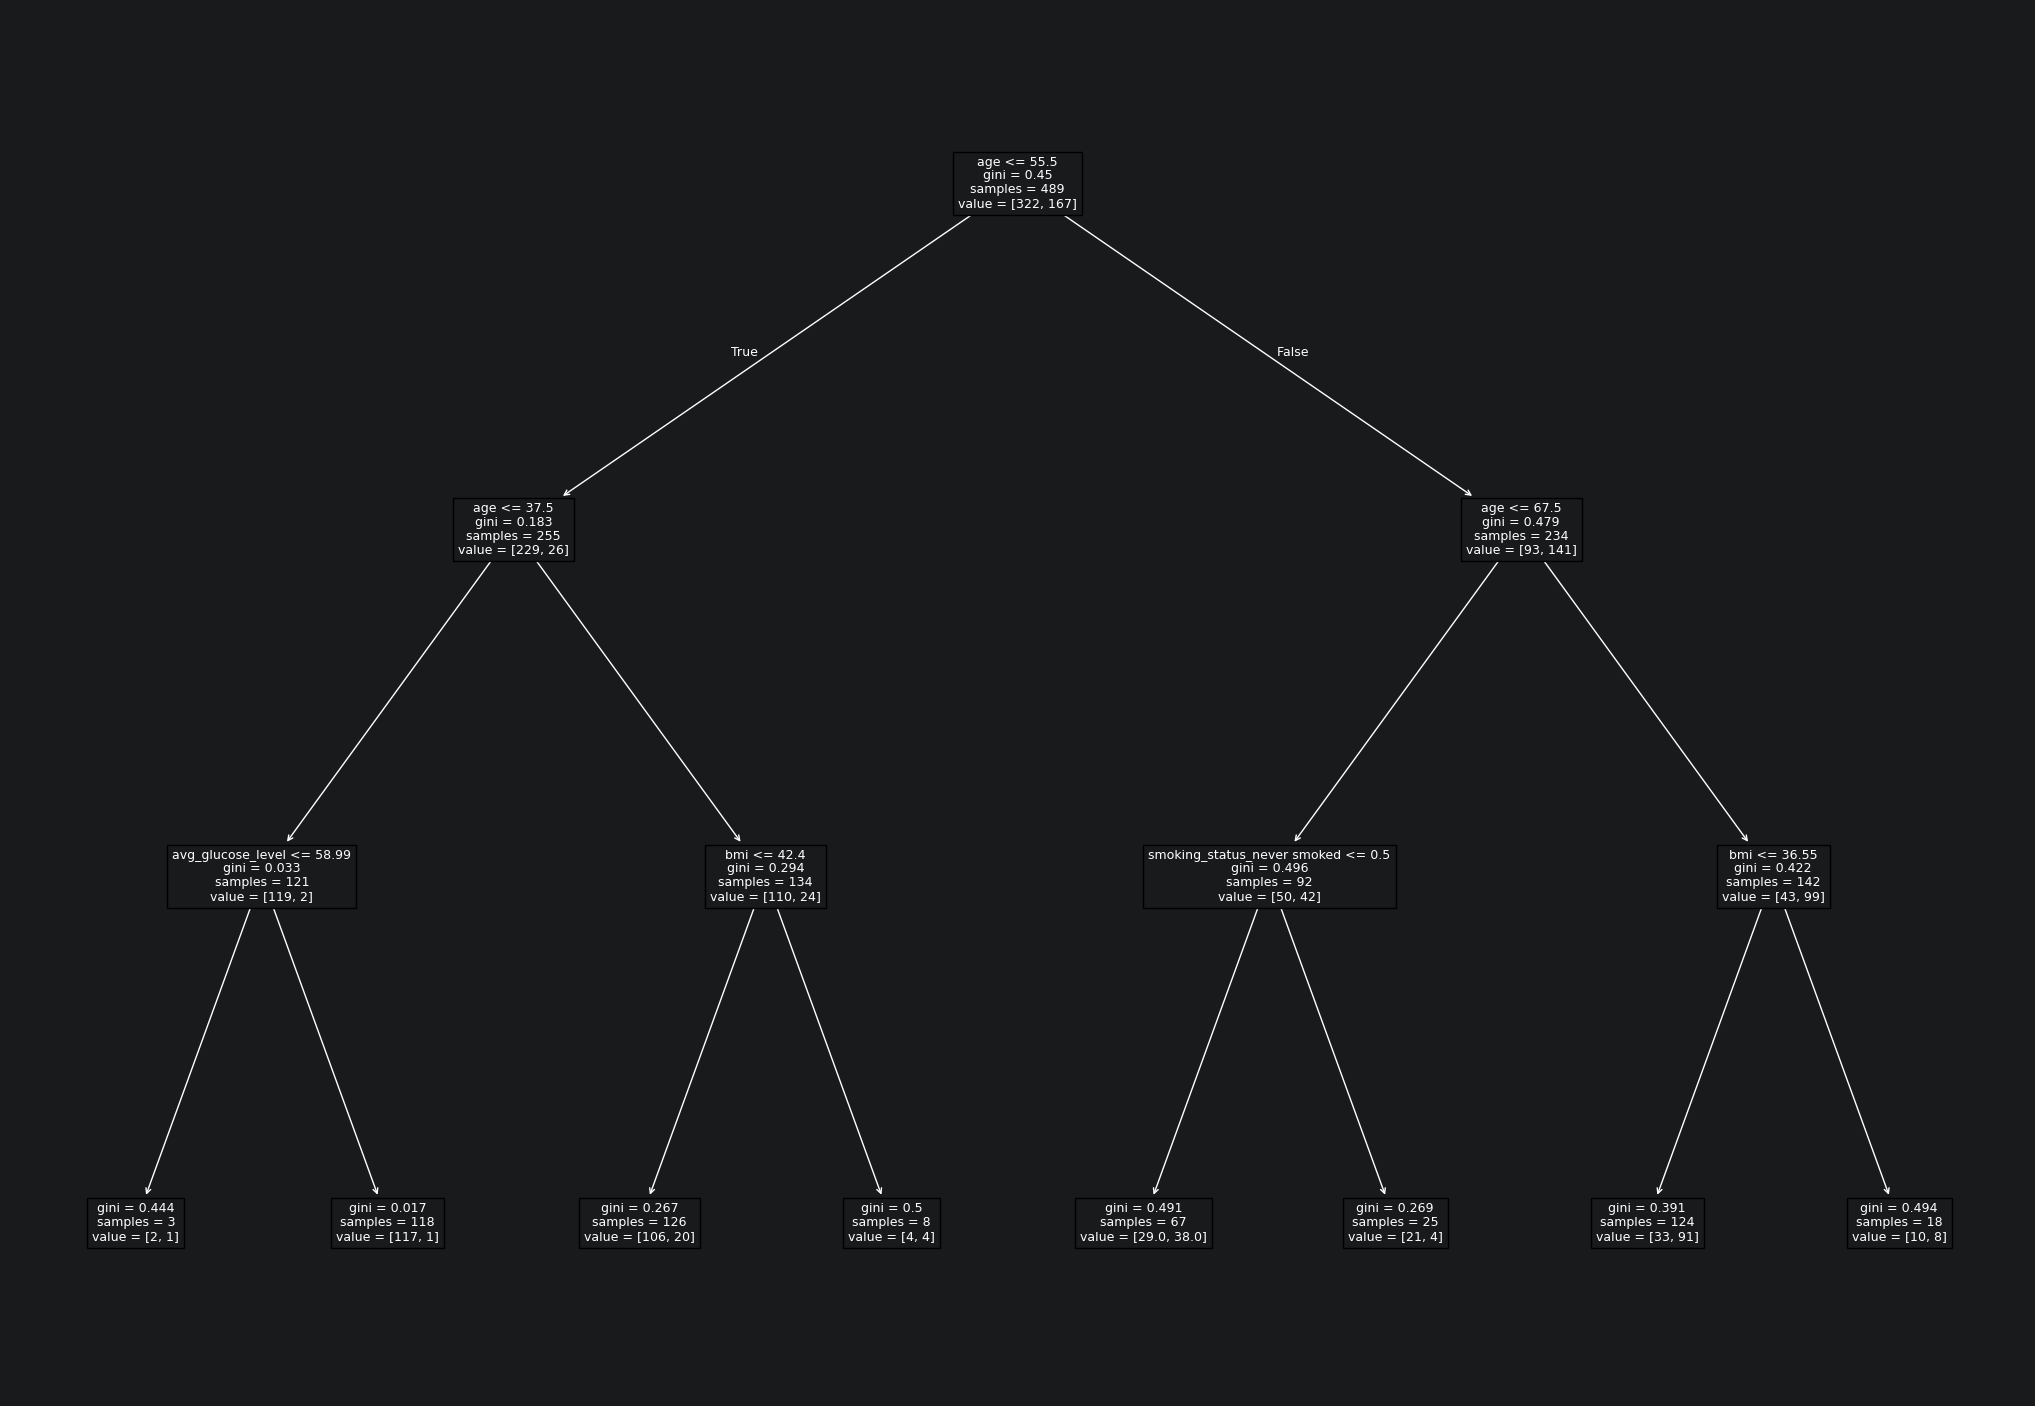

In [47]:
y_pred_train = model2.predict(X_train)
y_pred_test = model2.predict(X_test)

plt.figure(figsize=(26, 18))
plot_tree(model2, feature_names=X_train.columns)
plt.show()

`max_depth` = 5

In [48]:
model3 = DecisionTreeClassifier(max_depth=5)
model3.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


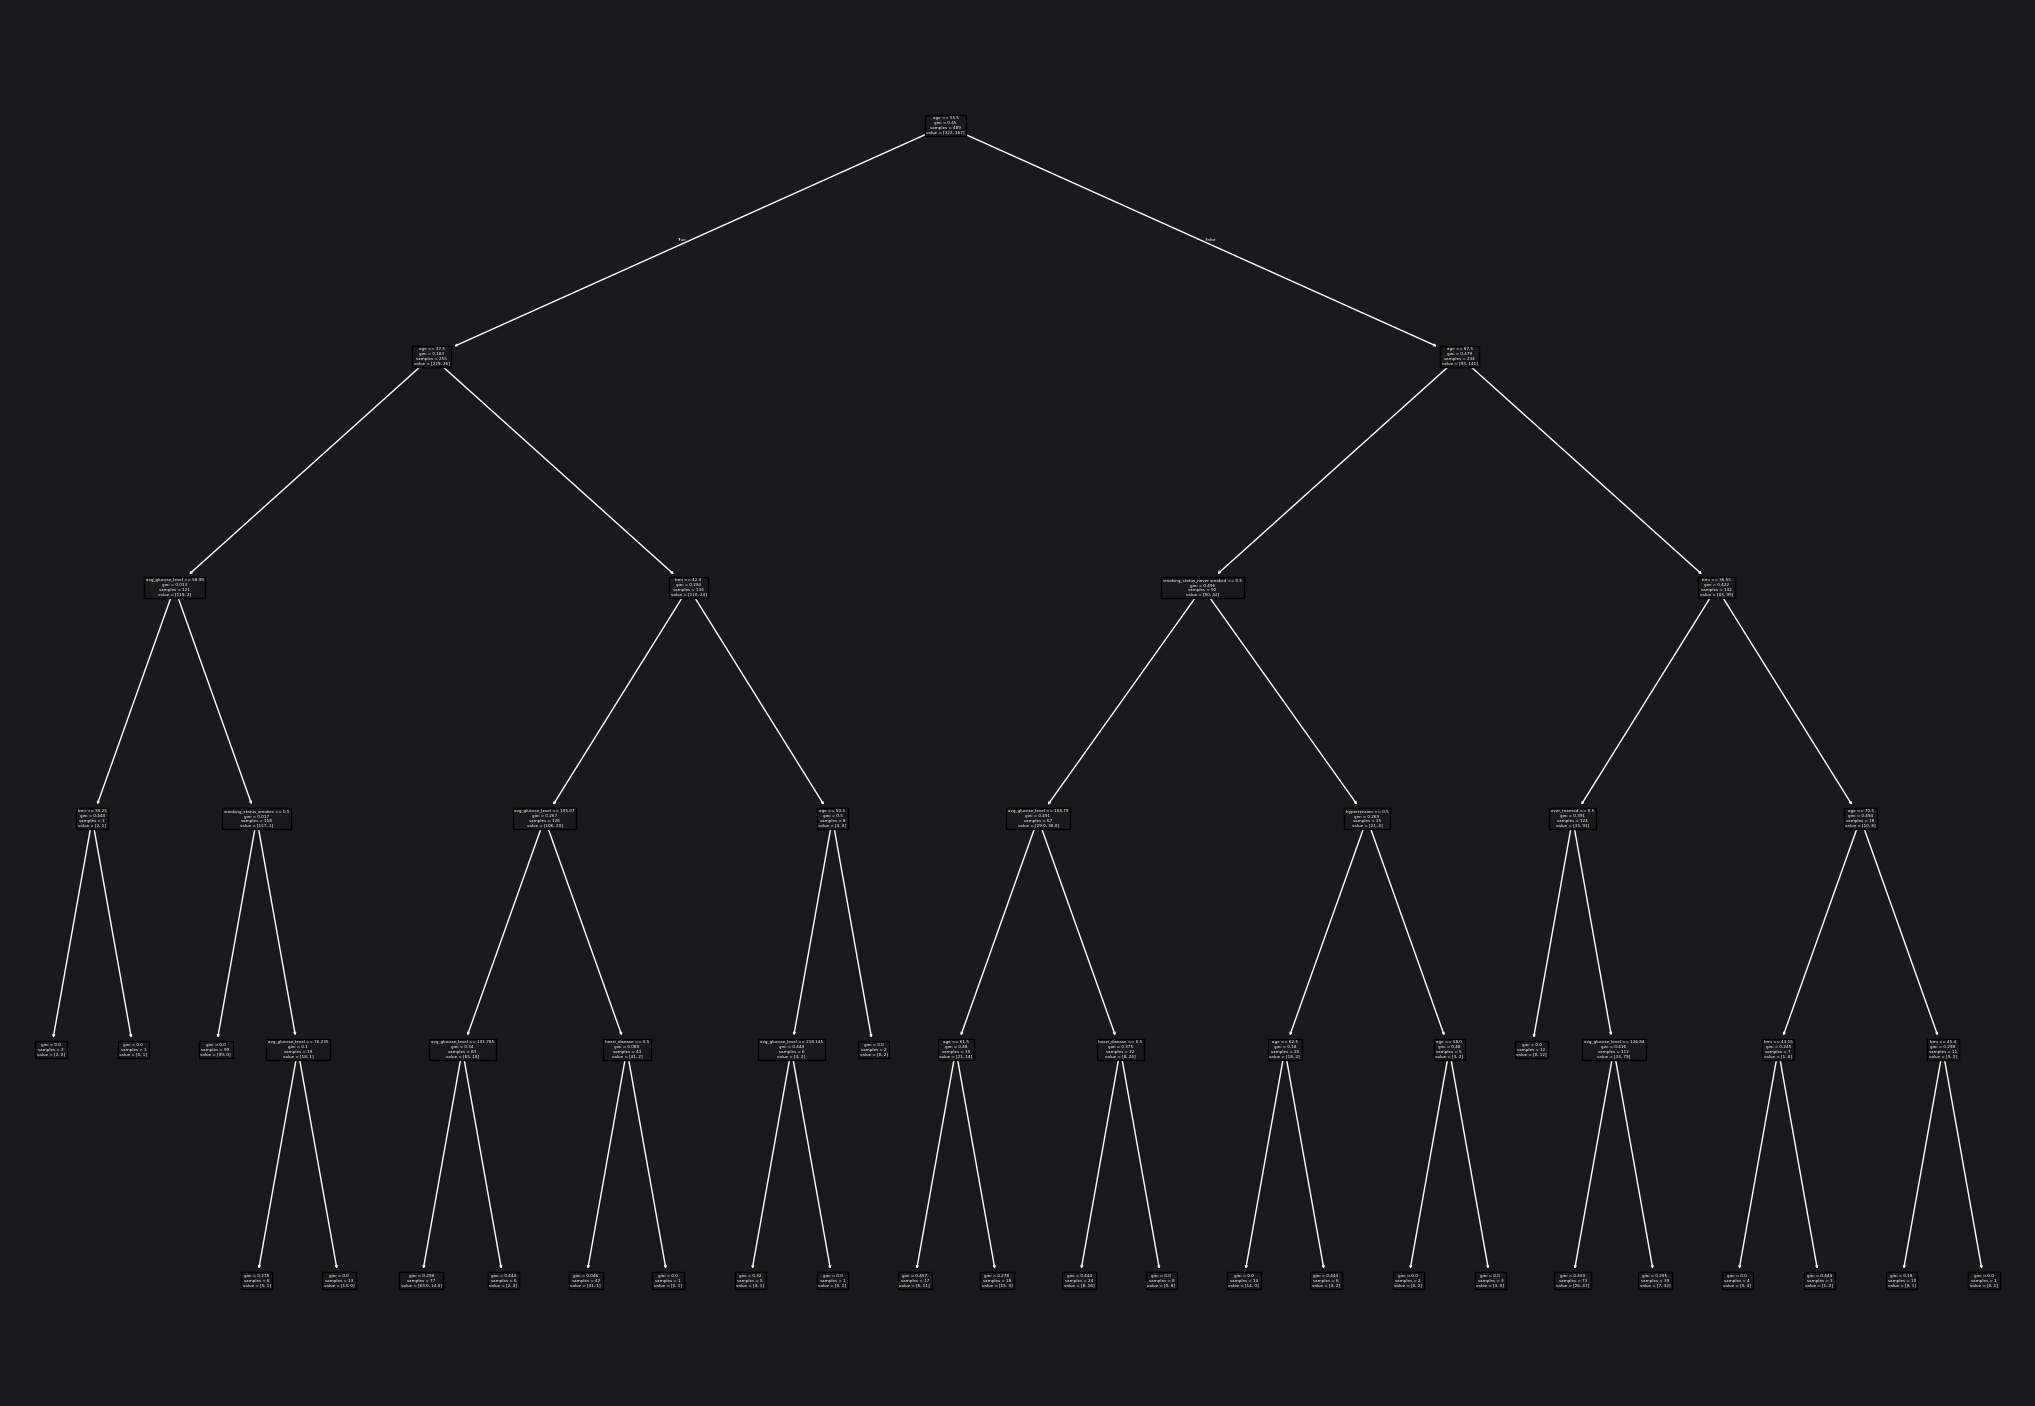

In [49]:
y_pred_train = model3.predict(X_train)
y_pred_test = model3.predict(X_test)

plt.figure(figsize=(26, 18))
plot_tree(model3, feature_names=X_train.columns)
plt.show()

### Ważność zmiennych

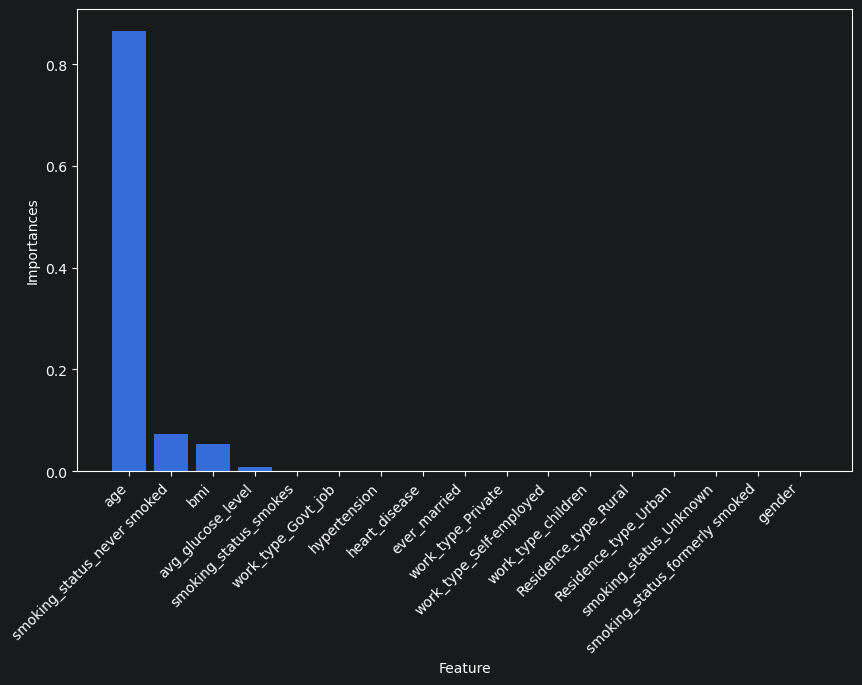

In [50]:
importance = model2.feature_importances_
sorted_idx = np.argsort(importance)[::-1]
plt.figure(figsize=(10, 6))
plt.bar(range(len(importance)), importance[sorted_idx])
plt.xticks(range(len(importance)), X_train.columns[sorted_idx], rotation=45, ha="right")
plt.xlabel("Feature")
plt.ylabel("Importances")
plt.show()